# Used Car Price Prediction — Capstone Project

**Author:** Musa Mlambo  
**Date:** 30 October 2026  
**GitHub:** https://github.com/musamlambo27-coder/used-car-price-prediction

### Contents
1. Problem Definition
2. Setup & Data Loading
3. Data Cleaning & Preprocessing
4. Exploratory Data Analysis (EDA)
5. Feature Engineering & Feature Selection
6. Model Development (baseline + improved models, cross-validation)
7. Hyperparameter Tuning
8. Error Analysis (overfitting / underfitting)
9. Save Final Model
10. Insights & Conclusion

## 1. Problem Definition

**Goal:** predict the asking price (`AskPrice`) of a used car from its listing details, so that buyers and sellers can tell whether a listing is fairly priced.

| Item | Choice |
|---|---|
| ML task | Supervised **regression** (target is a continuous price) |
| Target | `AskPrice` (₹) |
| Inputs | `Brand`, `model`, `Year`, `Age`, `kmDriven`, `Transmission`, `Owner`, `FuelType`, `PostedDate`, `AdditionInfo` |
| Primary metric | **RMSE** (₹) — penalises large mistakes, in the same unit as price |
| Secondary metrics | **MAE** (₹, typical error), **R²** (share of price variation explained), **Median % error** (easy to explain to non-technical audiences) |

**Approach:** clean the raw text fields into numbers → explore the data → engineer features → compare simple baseline models with tree-based models using a train/test split and 5-fold cross-validation → tune the best model → analyse its errors.

Because used-car prices are heavily right-skewed (a few luxury cars cost many times the median), models are trained on **log(price)** and predictions are converted back to ₹ for evaluation.

## 2. Setup & Data Loading

In [4]:
# --- Imports -----------------------------------------------------------------
import re
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (train_test_split, KFold, cross_validate,
                                     RandomizedSearchCV, learning_curve)
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.feature_selection import mutual_info_regression
from sklearn.inspection import permutation_importance

# Shared helpers (also used by the Streamlit app, so features are identical)
sys.path.append(str(Path.cwd()))
from src.features import (to_number, parse_posted_date, standardise_text, add_features,
                          TARGET, NUMERIC_FEATURES, CATEGORICAL_FEATURES,
                          BINARY_FEATURES, MODEL_FEATURES, TEXT_FLAGS)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

# --- Configuration -----------------------------------------------------------
DATA_PATH = Path("data/used_car_dataset.csv") 
FIG_DIR = Path("reports/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


def save_fig(name):
    """Save the current figure to reports/figures for the slides."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")


def rupees(x):
    return f"₹{x:,.0f}"

In [5]:
df_raw = pd.read_csv(DATA_PATH)
df_raw.columns = df_raw.columns.str.strip()
df_raw = df_raw.loc[:, ~df_raw.columns.str.startswith("Unnamed")]   # drop saved index columns

expected = {"Brand", "model", "Year", "Age", "kmDriven", "Transmission",
            "Owner", "FuelType", "PostedDate", "AdditionInfo", "AskPrice"}
missing_cols = expected - set(df_raw.columns)
assert not missing_cols, f"Columns not found in CSV: {missing_cols}"

print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")
display(df_raw.head())

Rows: 24,575 | Columns: 11


,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,NaN,NaN,"2,001.00",23.00,"98,000 km",NaN,NaN,Unknown,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,NaN,NaN,15.00,190000.0 km,Manual,NaN,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,NaN,"2,010.00",NaN,NaN,Manual,first,NaN,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,NaN,Swift,"2,017.00",7.00,NaN,Manual,second,Unknown,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,NaN,"2,019.00",5.00,NaN,Automatic,NaN,Unknown,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"


In [6]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 24575 entries, 0 to 24574
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         19306 non-null  str    
 1   model         14144 non-null  str    
 2   Year          19396 non-null  float64
 3   Age           18600 non-null  float64
 4   kmDriven      18344 non-null  str    
 5   Transmission  18653 non-null  str    
 6   Owner         13949 non-null  str    
 7   FuelType      19336 non-null  str    
 8   PostedDate    18355 non-null  str    
 9   AdditionInfo  24575 non-null  str    
 10  AskPrice      24575 non-null  str    
dtypes: float64(2), str(9)
memory usage: 4.2 MB


In [7]:
# Missing values and cardinality of every column
overview = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing": df_raw.isna().sum(),
    "missing_%": (df_raw.isna().mean() * 100).round(2),
    "unique_values": df_raw.nunique(),
    "example": df_raw.iloc[0],
})
display(overview)

,dtype,missing,missing_%,unique_values,example
Brand,str,5269,21.44,41,NaN
model,str,10431,42.45,403,NaN
Year,float64,5179,21.07,36,"2,001.00"
Age,float64,5975,24.31,33,23.00
kmDriven,str,6231,25.36,2303,"98,000 km"
Transmission,str,5922,24.10,2,NaN
Owner,str,10626,43.24,2,NaN
FuelType,str,5239,21.32,5,Unknown
PostedDate,str,6220,25.31,12,Nov-24
AdditionInfo,str,0,0.00,10676,"Honda City v teck in mint condition, valid gen..."


**The dataset is messy, which calls for the following cleaning plan:**
- `AskPrice` and `kmDriven` are **text** ("₹ 1,95,000", "98,000 km", "190000.0 km") and must be parsed into numbers.
- Missing data is hidden behind **placeholder values**: `"Unknown"` in `Brand`/`FuelType`, `Year = 9999` or `1900`, and unlikely ages such as 124.
- The same fuel type has **several labels** (`hybrid`, `Hybrid/CNG`).
- Many rows are **duplicates**, some exact and some copies of the same listing with different cells blanked out.
- `AdditionInfo` is **never missing** and usually contains the listing title, e.g. *"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, Diesel"* — brand, model, year and fuel. This is the key to recovering most missing values.

## 3. Data Cleaning & Preprocessing

Steps, each documented below:
1. Convert text columns to proper types; turn placeholder values into real missing values; merge duplicate labels
2. Remove exact duplicates, then merge near-duplicate copies of the same listing
3. Recover missing values from the seller text (`AdditionInfo`) — and check that this recovery is accurate
4. Handle the values that are still missing
5. Check consistency between `Year` and `Age`
6. Detect and handle outliers

In [8]:
df = df_raw.copy()
cleaning_log = [("Raw data", len(df))]

# 3.1a Type conversion ---------------------------------------------------------
df[TARGET] = to_number(df[TARGET])           # "₹ 1,95,000"  -> 195000.0
df["kmDriven"] = to_number(df["kmDriven"])   # "98,000 km"   -> 98000.0
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["PostedDate"] = parse_posted_date(df["PostedDate"])   # "Nov-24" -> 2024-11-01

# 3.1b Standardise text, and treat placeholders like "Unknown" as missing --------
PLACEHOLDERS = {"unknown", "na", "n/a", "none", "-", "?"}
for col in ["Brand", "model", "Transmission", "Owner", "FuelType"]:
    df[col] = standardise_text(df[col])
    df.loc[df[col].str.lower().isin(PLACEHOLDERS).fillna(False), col] = np.nan

# 3.1c The same model is often spelled differently ("tata-punch" vs "Punch",
#      "Wagon R" vs "Wagon-R"). Build a key without brand words, spaces or hyphens,
#      and map every spelling to the most common one.
brand_words = set(re.findall(r"[a-z]+", " ".join(df["Brand"].dropna().unique()).lower()))

def model_key(name):
    tokens = re.findall(r"[a-z0-9]+", str(name).lower())
    return "".join(t for t in tokens if t not in brand_words) or "".join(tokens)

models_known = df["model"].dropna()
canonical_model = models_known.groupby(models_known.map(model_key)).agg(lambda s: s.value_counts().index[0])
n_before = models_known.nunique()
df["model"] = df["model"].map(lambda m: canonical_model[model_key(m)] if pd.notna(m) else m)
print(f"Distinct model spellings: {n_before} -> {df['model'].nunique()}")

# 3.1d Merge duplicate labels/labels that mean the same thing
print("FuelType labels before:", df["FuelType"].value_counts(dropna=False).to_dict())
df["FuelType"] = df["FuelType"].replace({"hybrid": "Hybrid/CNG", "Hybrid": "Hybrid/CNG",
                                         "CNG": "Hybrid/CNG", "CNG & Hybrids": "Hybrid/CNG"})
print("FuelType labels after: ", df["FuelType"].value_counts(dropna=False).to_dict())

# 3.1e Impossible Year / Age values are placeholders (9999, 1900, age 124 ...)
REF_YEAR = int((df["Year"] + df["Age"]).mode()[0])   # Age is measured from this year
print(f"\nYear + Age = {REF_YEAR} in the data, so ages are measured from {REF_YEAR}.")
bad_year = (df["Year"] < 1990) | (df["Year"] > REF_YEAR)
bad_age = (df["Age"] < 0) | (df["Age"] > REF_YEAR - 1990)
print(f"Placeholder/impossible Year values set to missing: {bad_year.sum():,} "
      f"(e.g. {sorted(df.loc[bad_year, 'Year'].unique())[:5]})")
print(f"Impossible Age values set to missing: {bad_age.sum():,}")
df.loc[bad_year, "Year"] = np.nan
df.loc[bad_age, "Age"] = np.nan

Distinct model spellings: 400 -> 374
FuelType labels before: {nan: 10436, 'Petrol': 5447, 'Diesel': 4956, 'hybrid': 1998, 'Hybrid/CNG': 1738}
FuelType labels after:  {nan: 10436, 'Petrol': 5447, 'Diesel': 4956, 'Hybrid/CNG': 3736}

Year + Age = 2024 in the data, so ages are measured from 2024.
Placeholder/impossible Year values set to missing: 5,115 (e.g. [np.float64(1900.0), np.float64(1920.0), np.float64(1931.0), np.float64(1978.0), np.float64(1986.0)])
Impossible Age values set to missing: 4


In [9]:
# 3.2a Exact duplicates ----------------------------------------------------------
n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
cleaning_log.append(("After removing exact duplicates", len(df)))
print(f"Exact duplicate rows removed: {n_dup:,}")

# 3.2b Near-duplicates: the same listing (same seller text AND same price) copied
#      several times with different cells blanked out. Merge each group into one row,
#      keeping the first non-missing value of every column.
#      Safety rule: if copies disagree on kmDriven they may be genuinely different
#      cars, so those groups are left untouched.
key = ["AdditionInfo", TARGET]
example_key = df[df.duplicated(key, keep=False)].iloc[0][key]
print("\nExample near-duplicate group (before merging):")
display(df[(df["AdditionInfo"] == example_key["AdditionInfo"]) & (df[TARGET] == example_key[TARGET])])

km_conflict = df.groupby(key)["kmDriven"].transform("nunique") > 1
merged = df[~km_conflict].groupby(key, as_index=False, sort=False).first()
df = pd.concat([merged, df[km_conflict]], ignore_index=True)[df_raw.columns]
cleaning_log.append(("After merging near-duplicate listings", len(df)))
print(f"Rows after merging near-duplicates: {len(df):,}")

Exact duplicate rows removed: 9,592

Example near-duplicate group (before merging):


,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
5,BMW,NaN,"2,014.00",NaN,"83,000.00",NaN,first,NaN,2024-11-01,"BMW X3 2.0 XDRIVE 20D, 2014, Diesel","1,350,000.00"
11382,BMW,NaN,"2,014.00",10.00,"83,000.00",Automatic,first,Diesel,2024-11-01,"BMW X3 2.0 XDRIVE 20D, 2014, Diesel","1,350,000.00"


Rows after merging near-duplicates: 13,756


In [10]:
# 3.3 Recover missing values from the seller text ---------------------------------
missing_before = df[["Brand", "model", "Year", "Age", "FuelType", "Transmission"]].isna().sum()
text = df["AdditionInfo"].fillna("").str.lower()

# Lookup tables learned from rows where Brand and model ARE known
known = df.dropna(subset=["Brand", "model"])
model_to_brand = known.groupby("model")["Brand"].agg(lambda s: s.mode()[0])


def name_pattern(name):
    """'Wagon-R' -> regex matching 'wagon-r', 'wagon r' and 'wagonr' as whole words."""
    tokens = re.findall(r"[a-z0-9]+", name.lower())
    return re.compile(r"\b" + r"[\s\-]*".join(map(re.escape, tokens)) + r"\b")


MODEL_PATTERNS = [(m, name_pattern(m)) for m in sorted(model_to_brand.index, key=len, reverse=True)]
BRAND_PATTERNS = ([(b, name_pattern(b)) for b in sorted(known["Brand"].unique(), key=len, reverse=True)]
                  + [("Maruti Suzuki", re.compile(r"\bmaruti\b")),
                     ("Mercedes-Benz", re.compile(r"\bmercedes\b|\bbenz\b"))])


def extract_year(t):
    years = t.str.extract(r",\s*((?:19|20)\d\d)\s*,")[0]
    years = years.fillna(t.str.extract(r"\b((?:199|20[0-2])\d)\b")[0]).astype(float)
    return years.where(years.between(1990, REF_YEAR))


def extract_fuel(t):
    fuel = t.str.extract(r",\s*(petrol|diesel|cng & hybrids|electric|lpg)\s*$")[0]
    fuel = fuel.fillna(t.str.extract(r"\b(petrol|diesel|cng|hybrid|electric)\b")[0])
    return fuel.map({"petrol": "Petrol", "diesel": "Diesel"}).fillna(fuel.notna().map({True: "Hybrid/CNG"}))


def extract_transmission(t):
    auto = t.str.contains(r"\b(?:at|amt|cvt|dct|dsg|automatic|ivt|tiptronic|steptronic)\b")
    manual = t.str.contains(r"\b(?:mt|manual)\b")
    labels = np.select([auto & ~manual, manual & ~auto], ["Automatic", "Manual"], default="")
    return pd.Series(labels, index=t.index).replace("", np.nan)


def extract_brand(t):
    for brand, pattern in BRAND_PATTERNS:
        if pattern.search(t):
            return brand
    return np.nan


def extract_model(t, brand):
    """Longest known model name in the text (so 'Grand i10' wins over 'i10')."""
    for model, pattern in MODEL_PATTERNS:
        same_brand = pd.isna(brand) or model_to_brand[model] == brand
        long_enough = len(model) >= 3 or not pd.isna(brand)   # avoid 'A4'-style false hits
        if same_brand and long_enough and pattern.search(t):
            return model
    return np.nan


# Fill gaps only — values already present are never overwritten
df["Year"] = df["Year"].fillna(REF_YEAR - df["Age"]).fillna(extract_year(text))
df["Age"] = df["Age"].fillna(REF_YEAR - df["Year"])
df["FuelType"] = df["FuelType"].fillna(extract_fuel(text))
df["Transmission"] = df["Transmission"].fillna(extract_transmission(text))
df["Brand"] = df["Brand"].fillna(df["model"].map(model_to_brand))
need = df["Brand"].isna()
df.loc[need, "Brand"] = [extract_brand(t) for t in text[need]]
need = df["model"].isna()
df.loc[need, "model"] = [extract_model(t, b) for t, b in zip(text[need], df.loc[need, "Brand"])]
df["Brand"] = df["Brand"].fillna(df["model"].map(model_to_brand))

missing_after = df[missing_before.index].isna().sum()
recovery = pd.DataFrame({"missing_before": missing_before, "missing_after": missing_after})
recovery["recovered_%"] = (1 - recovery["missing_after"] / recovery["missing_before"]) * 100
display(recovery)

,missing_before,missing_after,recovered_%
Brand,4480,73,98.37
model,4486,253,94.36
Year,4425,77,98.26
Age,2512,77,96.93
FuelType,4474,482,89.23
Transmission,2506,1923,23.26


In [11]:
# Is the text recovery accurate? Test it on rows where the TRUE value is known:
# pretend the value is missing, extract it from the text, and compare.
check = df_raw.drop_duplicates().copy()
check_text = check["AdditionInfo"].fillna("").str.lower()
truth_fuel = standardise_text(check["FuelType"]).replace({"hybrid": "Hybrid/CNG"})
truth_trans = standardise_text(check["Transmission"])
truth_brand = standardise_text(check["Brand"])
sample = truth_brand.dropna()[lambda s: s.ne("Unknown")].sample(2000, random_state=RANDOM_STATE).index

accuracy = {}
for name, truth, guess in [
        ("Year", pd.to_numeric(check["Year"], errors="coerce").where(lambda s: s.between(1990, REF_YEAR)),
         extract_year(check_text)),
        ("FuelType", truth_fuel.where(truth_fuel.isin(["Petrol", "Diesel", "Hybrid/CNG"])), extract_fuel(check_text)),
        ("Transmission", truth_trans, extract_transmission(check_text)),
        ("Brand", truth_brand.loc[sample], pd.Series([extract_brand(t) for t in check_text[sample]], index=sample))]:
    both = truth.notna() & guess.reindex(truth.index).notna()
    accuracy[name] = {"rows checked": int(both.sum()),
                      "accuracy_%": (truth[both] == guess.reindex(truth.index)[both]).mean() * 100}
display(pd.DataFrame(accuracy).T.style.format({"rows checked": "{:,.0f}", "accuracy_%": "{:.1f}%"}))

,rows checked,accuracy_%
Year,"9,230",99.8%
FuelType,"8,830",99.6%
Transmission,"2,998",96.7%
Brand,"1,912",99.8%


**Missing-value strategy:**
- **Recovered from text** where the seller's title states it. The accuracy check above compares extracted values with values that were already known, so we know the recovery is trustworthy before relying on it.
- Rows that still have **no brand or no age** are **dropped**: these are the two strongest price signals, and these rows are usually vague text like "Good condition" with nothing to recover.
- Remaining gaps in `kmDriven`, `Transmission`, `Owner`, `FuelType` and `model` are filled **inside the modelling pipeline** (median for numbers, an `"Unknown"` category for text). Learning the fill values inside the pipeline means they come from training data only — no leakage from the test set.

In [12]:
# 3.4 Values still missing ----------------------------------------------------------
df = df.dropna(subset=[TARGET, "Brand", "Age"]).reset_index(drop=True)
cleaning_log.append(("After dropping rows with no brand/age", len(df)))
print("Missing values left (handled by the pipeline):")
print(df[["Brand", "model", "Age", "kmDriven", "Transmission", "Owner", "FuelType"]].isna().sum())

# 3.5 Consistency: Age must equal REF_YEAR - Year for every row
print(f"\nRows where Age != {REF_YEAR} - Year: {((REF_YEAR - df['Year']) != df['Age']).sum()}")
print(f"Correlation between Year and Age: {df['Year'].corr(df['Age']):.3f}")

Missing values left (handled by the pipeline):
Brand              0
model            167
Age                0
kmDriven        2582
Transmission    1893
Owner           4536
FuelType         426
dtype: int64

Rows where Age != 2024 - Year: 1
Correlation between Year and Age: -1.000


`Year` and `Age` carry exactly the same information (Age = 2024 − Year, correlation −1). Keeping both would double-count one signal, so **only `Age` is kept** as a model feature.

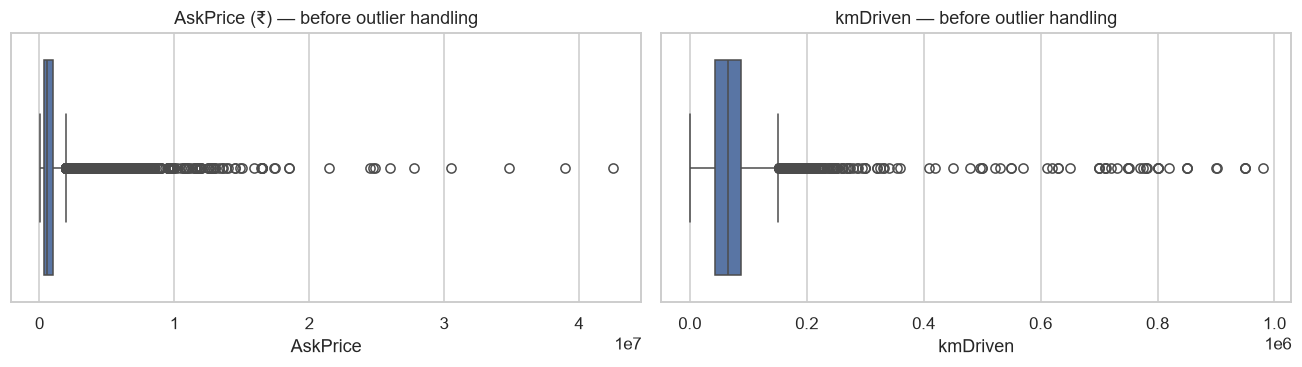

In [13]:
# 3.6 Outliers — look first --------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.boxplot(x=df[TARGET], ax=axes[0]); axes[0].set_title("AskPrice (₹) — before outlier handling")
sns.boxplot(x=df["kmDriven"], ax=axes[1]); axes[1].set_title("kmDriven — before outlier handling")
save_fig("outliers_before"); plt.show()

kmDriven values treated as data-entry errors: 53
Price fences: ₹13,566 to ₹24,937,653
Price outliers removed: 6 (0.04% of rows)


,Brand,model,Age,AskPrice
765,Mercedes-Benz,G-Class,5.00,"26,000,000.00"
910,Lexus,NaN,0.00,"27,750,000.00"
3067,Rolls-Royce,Phantom Series II,9.00,"42,500,000.00"
9164,Mercedes-Benz,G-Class,0.00,"30,500,000.00"
11296,Lamborghini,Urus,3.00,"39,000,000.00"
11815,Mercedes-Benz,G-Class,1.00,"34,800,000.00"



Non-car / implausible listings removed: 14


,Brand,Age,AskPrice,AdditionInfo
2794,Maruti Suzuki,0.00,"18,500.00",Panasound brand Daimond 2k androd stereo
3574,Mercedes-Benz,3.00,"38,000.00",Mercedes-Benz GLS 2021
4878,Honda,4.00,"49,000.00","Honda WR-V [2020-2023] 1.5 SV i-DTEC MT, 2020,..."
5171,Maruti Suzuki,4.00,"49,999.00",Maruti Suzuki Wagon R 2000
8090,Kia,0.00,"45,000.00",Kia CERATO 2024
9213,Maruti Suzuki,1.00,"15,000.00",Breeza Rim
10636,Mahindra,0.00,"21,000.00","THAR ROXX, New THAR , XUV 3XO,XUV700, SCORPIO ..."
10962,Toyota,1.00,"48,000.00",GOLD CHAINS AND HAAR FOR WOMEN AND MEN
11728,Hyundai,7.00,"30,000.00",Hyundai Accent 2017 CNG & Hybrids 12000 Km Driven
12077,BMW,10.00,"15,000.00",BMW 5 Series 2014


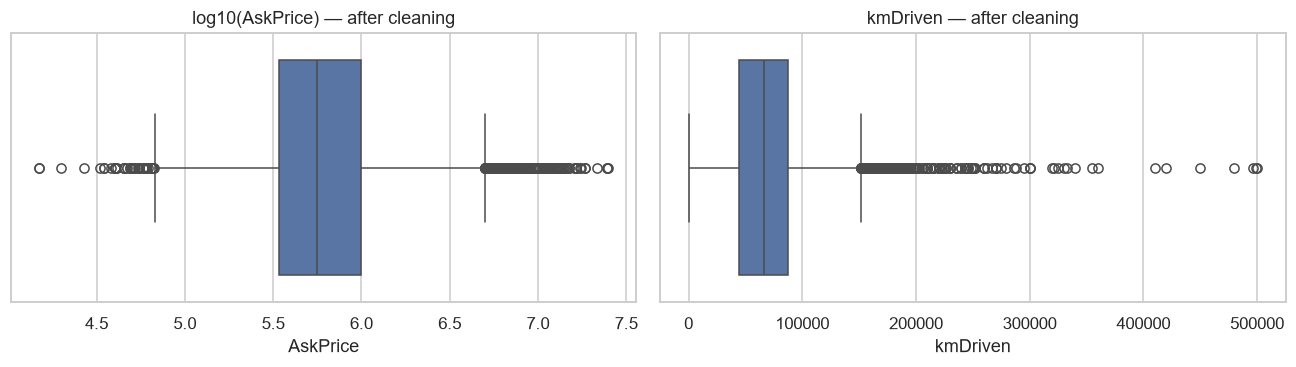

In [14]:
# 3.6 Outliers — handle -------------------------------------------------------------
# a) kmDriven: above 500,000 km, or 0 km on a car older than 1 year, is almost
#    certainly a typing error. Set to missing (imputed later) rather than deleting
#    the whole listing.
km_error = (df["kmDriven"] > 500_000) | ((df["kmDriven"] == 0) & (df["Age"] > 1))
df.loc[km_error, "kmDriven"] = np.nan
print(f"kmDriven values treated as data-entry errors: {km_error.sum()}")

# b) AskPrice: prices are log-normally distributed, so apply the IQR rule on
#    log(price) with wide 3×IQR fences. This removes only extreme values — a
#    handful of supercars too rare for the model to learn from.
log_price = np.log(df[TARGET])
q1, q3 = log_price.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = np.exp(q1 - 3 * iqr), np.exp(q3 + 3 * iqr)
price_outlier = (df[TARGET] < max(low, 10_000)) | (df[TARGET] > high)
print(f"Price fences: {rupees(max(low, 10_000))} to {rupees(high)}")
print(f"Price outliers removed: {price_outlier.sum()} ({price_outlier.mean():.2%} of rows)")
display(df.loc[price_outlier, ["Brand", "model", "Age", TARGET]].head(10))
df = df[~price_outlier].reset_index(drop=True)
cleaning_log.append(("After removing price outliers", len(df)))

# c) Ads that are not for a working car (stereos, rims, scrap, jewellery ...).
#    A car 10 years old or newer listed under ₹50,000 is not a plausible price.
junk = (df[TARGET] < 50_000) & (df["Age"] <= 10)
print(f"\nNon-car / implausible listings removed: {junk.sum()}")
display(df.loc[junk, ["Brand", "Age", TARGET, "AdditionInfo"]])
df = df[~junk].reset_index(drop=True)
cleaning_log.append(("After removing non-car listings", len(df)))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.boxplot(x=np.log10(df[TARGET]), ax=axes[0]); axes[0].set_title("log10(AskPrice) — after cleaning")
sns.boxplot(x=df["kmDriven"], ax=axes[1]); axes[1].set_title("kmDriven — after cleaning")
save_fig("outliers_after"); plt.show()

In [15]:
# Cleaning summary
log_df = pd.DataFrame(cleaning_log, columns=["Step", "Rows"])
log_df["Rows removed"] = -log_df["Rows"].diff().fillna(0).astype(int)
display(log_df)
print(f"Kept {len(df):,} unique listings out of {len(df_raw):,} raw rows.")

,Step,Rows,Rows removed
0,Raw data,24575,0
1,After removing exact duplicates,14983,9592
2,After merging near-duplicate listings,13756,1227
3,After dropping rows with no brand/age,13611,145
4,After removing price outliers,13605,6
5,After removing non-car listings,13591,14


Kept 13,591 unique listings out of 24,575 raw rows.


## 4. Exploratory Data Analysis (EDA)

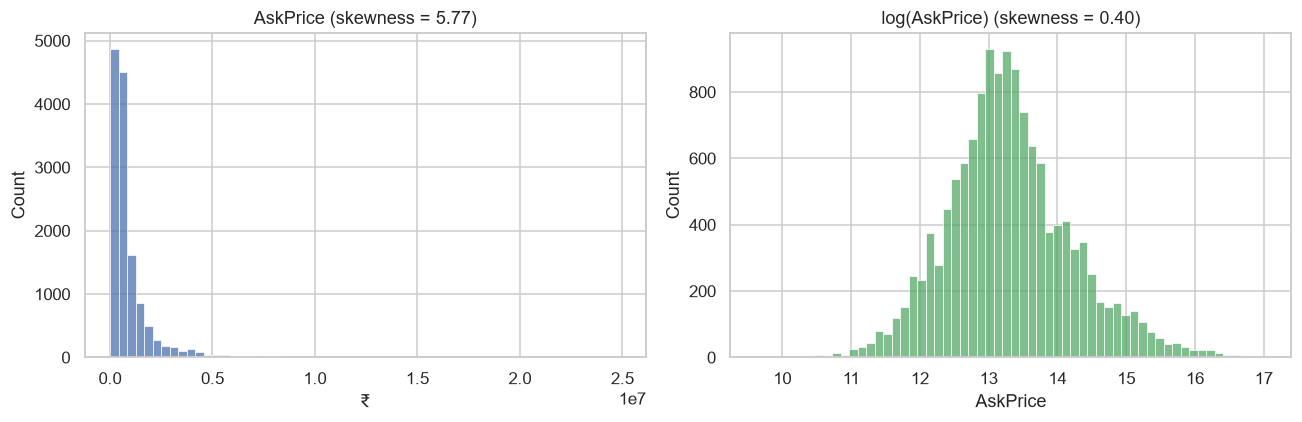

Median price: ₹560,000 | Mean price: ₹967,327


In [16]:
# 4.1 Target distribution: raw vs log scale
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], bins=60, ax=axes[0])
axes[0].set_title(f"AskPrice (skewness = {df[TARGET].skew():.2f})"); axes[0].set_xlabel("₹")
sns.histplot(np.log1p(df[TARGET]), bins=60, ax=axes[1], color="C2")
axes[1].set_title(f"log(AskPrice) (skewness = {np.log1p(df[TARGET]).skew():.2f})")
save_fig("target_distribution"); plt.show()
print(f"Median price: {rupees(df[TARGET].median())} | Mean price: {rupees(df[TARGET].mean())}")

**Insight:** prices are strongly **right-skewed** — which suggests that the mean is pulled well above the median by a small number of expensive cars. After a log transform the distribution is close to bell-shaped. This is why the models predict **log(price)**: errors become *relative* (10% off on a cheap car counts like 10% off on an expensive car) and linear models fit better.

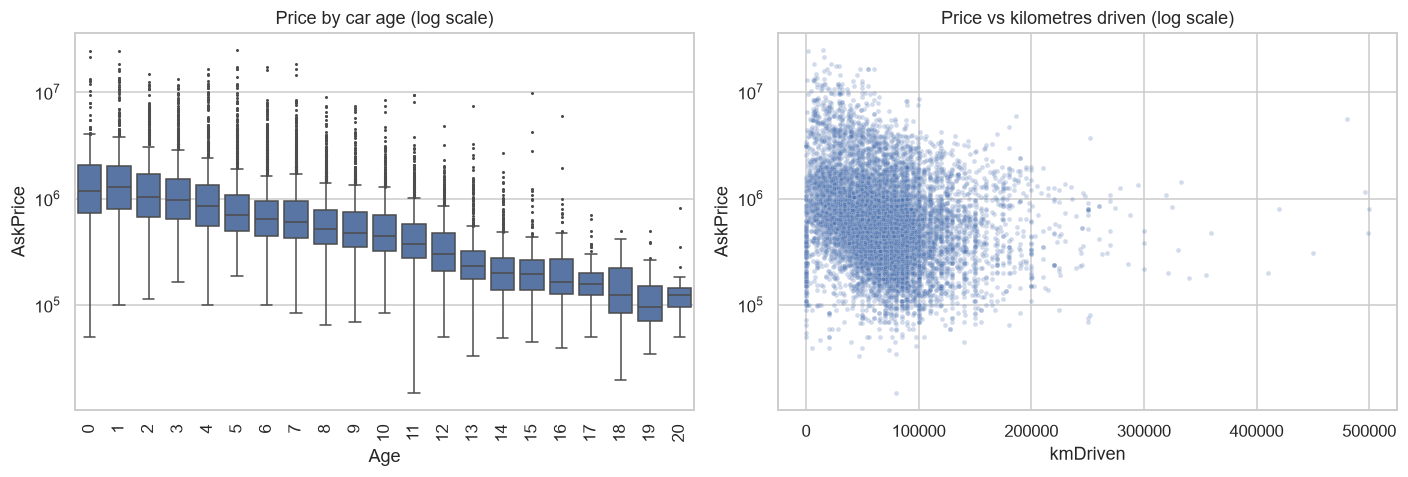

Spearman correlation, Age vs price: -0.60
Spearman correlation, kmDriven vs price: -0.25
Median price falls roughly 12.1% per year of age (first 15 years).


In [17]:
# 4.2 Price vs Age and kmDriven
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df[df["Age"] <= 20].astype({"Age": int}), x="Age", y=TARGET, ax=axes[0], color="C0", fliersize=1)
axes[0].set_yscale("log"); axes[0].set_title("Price by car age (log scale)")
axes[0].tick_params(axis="x", rotation=90)
sns.scatterplot(data=df, x="kmDriven", y=TARGET, alpha=0.25, s=10, ax=axes[1])
axes[1].set_yscale("log"); axes[1].set_title("Price vs kilometres driven (log scale)")
save_fig("price_vs_age_km"); plt.show()

yearly = df.groupby("Age")[TARGET].median()
yearly = yearly[yearly.index <= 15]
annual_drop = 1 - np.exp(np.polyfit(yearly.index, np.log(yearly.values), 1)[0])
print(f"Spearman correlation, Age vs price: {df['Age'].corr(df[TARGET], method='spearman'):.2f}")
print(f"Spearman correlation, kmDriven vs price: {df['kmDriven'].corr(df[TARGET], method='spearman'):.2f}")
print(f"Median price falls roughly {annual_drop:.1%} per year of age (first 15 years).")

**Insight:** age is the clearest single driver of price (Spearman −0.60). The median asking price falls by roughly **12% per year** — a 5-year-old car typically lists at a bit over half its new-car level. Kilometres driven also lowers price (Spearman −0.25), but the relationship is much noisier, partly because km and age rise together.

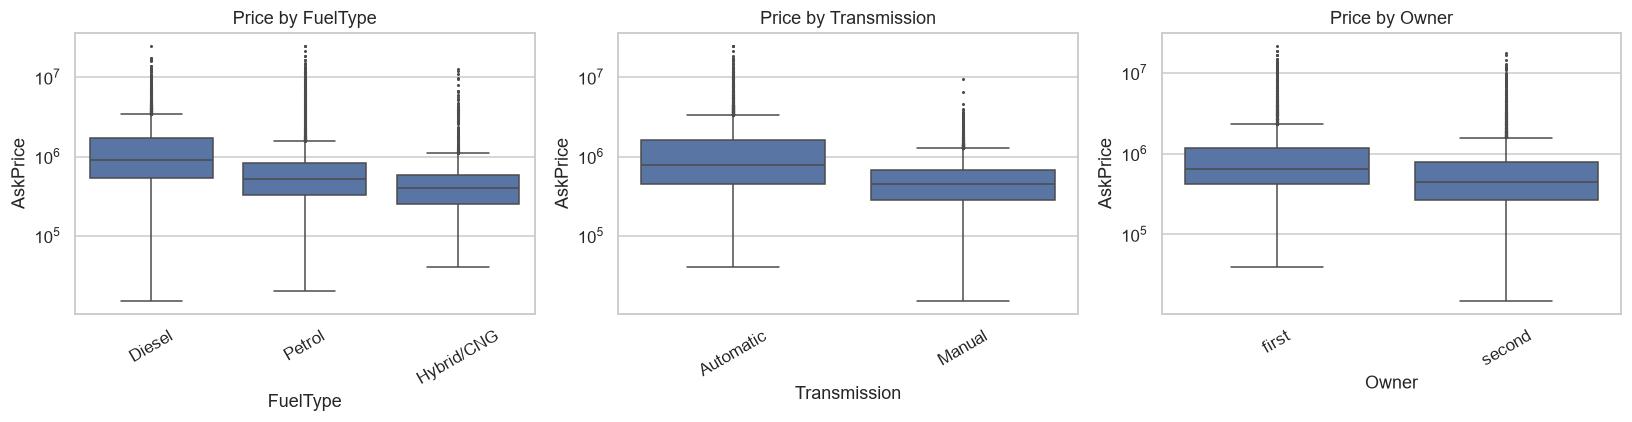

,count,median
FuelType,,
Diesel,4646,"₹895,000"
Petrol,5154,"₹517,800"
Hybrid/CNG,3368,"₹399,999"


,count,median
Transmission,,
Automatic,6004,"₹775,000"
Manual,5695,"₹450,000"


,count,median
Owner,,
first,4239,"₹650,000"
second,4817,"₹450,000"


In [18]:
# 4.3 Price by categorical features
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["FuelType", "Transmission", "Owner"]):
    order = df.groupby(col)[TARGET].median().sort_values(ascending=False).index
    sns.boxplot(data=df, x=col, y=TARGET, order=order, ax=ax, fliersize=1)
    ax.set_yscale("log"); ax.set_title(f"Price by {col}"); ax.tick_params(axis="x", rotation=30)
save_fig("price_by_category"); plt.show()

for col in ["FuelType", "Transmission", "Owner"]:
    summary = df.groupby(col)[TARGET].agg(["count", "median"]).sort_values("median", ascending=False)
    summary["median"] = summary["median"].map(rupees)
    display(summary)

**Insight:**
- **Transmission:** automatics have a median of **₹7.75 lakh** vs **₹4.5 lakh** for manuals (+72%).
- **Fuel:** diesel cars list highest (**₹8.95 lakh** median), then petrol (₹5.18 lakh) and hybrid/CNG (₹4.0 lakh).
- **Owner:** first-owner cars list at **₹6.5 lakh** vs ₹4.5 lakh for second-owner cars.

These are raw medians, so they partly overlap with other factors (luxury cars are usually automatic and diesel). The model separates these effects by using all features together.

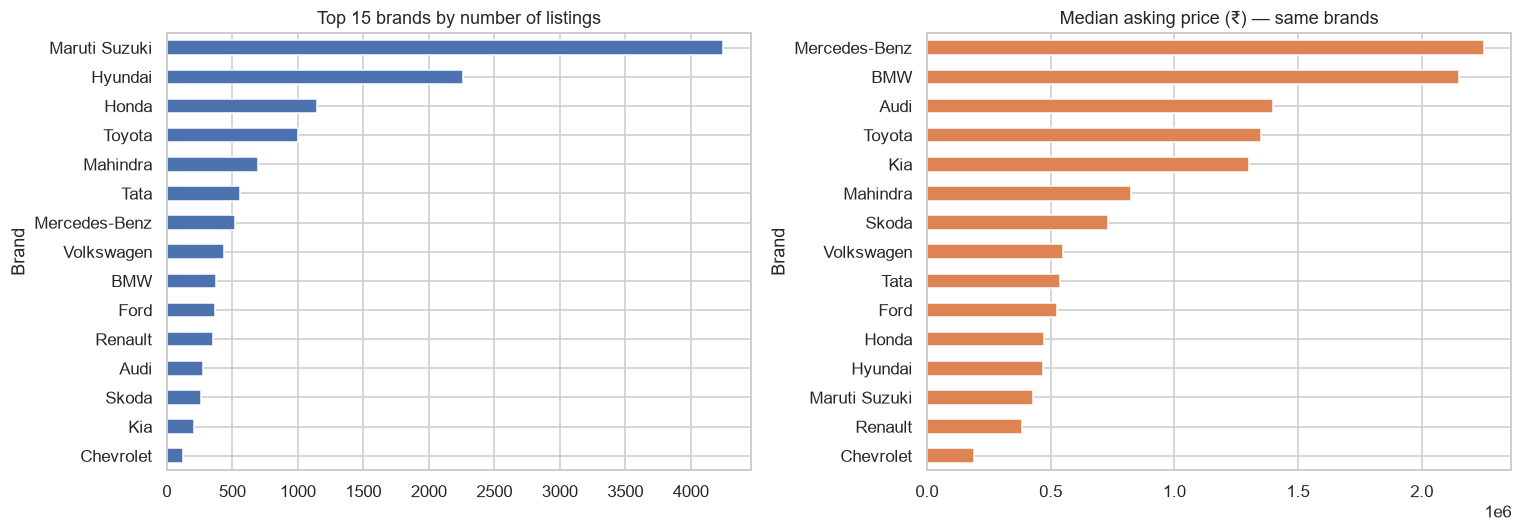

Number of brands: 38 | number of models: 366


In [19]:
# 4.4 Brands: popularity and price level
top_brands = df["Brand"].value_counts().head(15).index
brand_stats = (df[df["Brand"].isin(top_brands)]
               .groupby("Brand")[TARGET].agg(listings="count", median_price="median")
               .sort_values("median_price", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
brand_stats["listings"].sort_values().plot.barh(ax=axes[0], color="C0")
axes[0].set_title("Top 15 brands by number of listings")
brand_stats["median_price"].sort_values().plot.barh(ax=axes[1], color="C1")
axes[1].set_title("Median asking price (₹) — same brands")
save_fig("brands"); plt.show()
print(f"Number of brands: {df['Brand'].nunique()} | number of models: {df['model'].nunique()}")

**Insight:** Maruti Suzuki and Hyundai dominate the listings, while luxury brands have far fewer listings but much higher prices — luxury-brand cars have a median price about **4× higher** than everything else (Section 5). Brand (and model within brand) therefore carries a lot of price information. `model` has many unique values, so rare models will be grouped into an "infrequent" bucket during encoding.

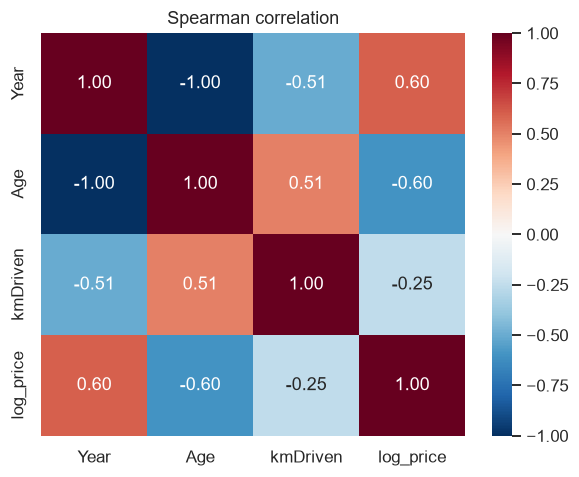

In [20]:
# 4.5 Correlation between numeric variables
num_view = df[["Year", "Age", "kmDriven"]].assign(log_price=np.log1p(df[TARGET]))
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(num_view.corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Spearman correlation"); save_fig("correlation"); plt.show()

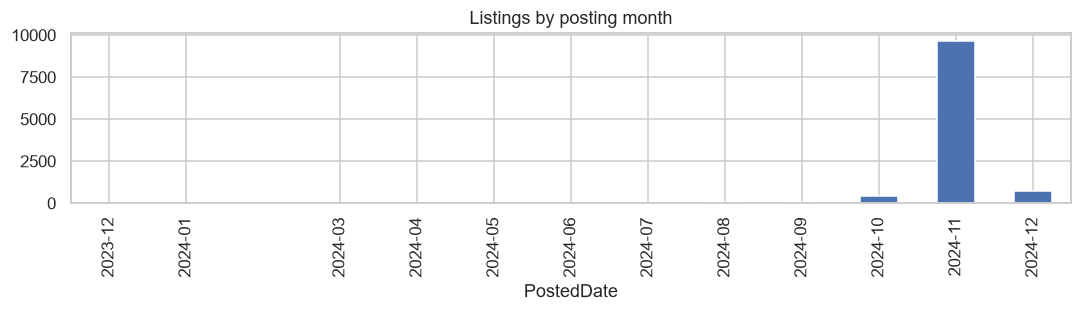

Listings span 2023-12 to 2024-12 (12 months).


In [21]:
# 4.6 When were the listings posted?
posted = df["PostedDate"].dt.to_period("M").value_counts().sort_index()
posted.plot(kind="bar", figsize=(10, 3), title="Listings by posting month")
save_fig("posted_dates"); plt.show()
print(f"Listings span {posted.index.min()} to {posted.index.max()} ({len(posted)} months).")

**Insight:** the great majority of listings were posted in November 2024, so `PostedDate` is not useful for capturing market trends. It is used only to sanity-check `Age`, then dropped.

## 5. Feature Engineering & Feature Selection

Candidate features (code in `src/features.py`, shared with the Streamlit app). Most come from the seller's text, which holds details the structured columns don't:

| New feature | Definition | Why it may help |
|---|---|---|
| `km_per_year` | `kmDriven / max(Age, 1)` | Separates gently-used cars from heavily-used ones of the same age |
| `engine_litres` | Engine size from the title, e.g. "Innova **2.5** G" | Bigger engines = higher trim/segment; differs *within* the same model |
| `is_luxury` | Brand is premium (BMW, Mercedes-Benz, Audi, Land Rover …) | Premium brands sit at a much higher price level |
| `is_4x4` | Text mentions 4x4 / AWD / xDrive / 4MATIC … | Four-wheel-drive variants cost more |
| `is_7_seater` | Text mentions 7/8 seats | Larger vehicles cost more |
| `is_dealer_listing` | Text is a structured title "…, 2015, Petrol" | These look like dealer/platform listings, which tend to price differently from casual private ads |
| `mentions_good_condition` | "mint", "excellent", "well maintained" … | Seller's own condition claim |
| `mentions_service_history`, `mentions_insurance`, `mentions_accident` | Keyword flags | Maintenance, insurance and damage would matter — *if* sellers mention them |

In [22]:
df = add_features(df)
binary_candidates = ["is_luxury"] + list(TEXT_FLAGS)
display(df[["km_per_year", "engine_litres"]].describe().T)
print(f"engine_litres found for {df['engine_litres'].notna().mean():.0%} of listings | "
      f"Spearman with price: {df['engine_litres'].corr(df[TARGET], method='spearman'):.2f}")
print(f"km_per_year Spearman with price: {df['km_per_year'].corr(df[TARGET], method='spearman'):.2f}")

# Do the binary flags separate prices, and are they common enough to learn from?
rows = []
for flag in binary_candidates:
    with_flag, without = df.loc[df[flag] == 1, TARGET], df.loc[df[flag] == 0, TARGET]
    rows.append({"feature": flag, "listings_with_flag": int(df[flag].sum()),
                 "share_%": df[flag].mean() * 100,
                 "median_price_if_1": with_flag.median(), "median_price_if_0": without.median()})
flag_effect = pd.DataFrame(rows).set_index("feature")
flag_effect["price_ratio"] = flag_effect["median_price_if_1"] / flag_effect["median_price_if_0"]
display(flag_effect.style.format({"share_%": "{:.2f}%", "median_price_if_1": "₹{:,.0f}",
                                  "median_price_if_0": "₹{:,.0f}", "price_ratio": "{:.2f}×"}))

,count,mean,std,min,25%,50%,75%,max
km_per_year,"10,962.00","10,939.05","8,628.85",0.00,"6,307.51","9,000.00","13,000.00","200,040.00"
engine_litres,"4,610.00",1.66,0.60,0.80,1.20,1.50,2.00,6.50


engine_litres found for 34% of listings | Spearman with price: 0.65
km_per_year Spearman with price: 0.34


,listings_with_flag,share_%,median_price_if_1,median_price_if_0,price_ratio
feature,,,,,
is_luxury,1564,11.51%,"₹2,050,000","₹500,000",4.10×
is_4x4,486,3.58%,"₹2,100,000","₹549,000",3.83×
is_7_seater,329,2.42%,"₹1,250,000","₹550,000",2.27×
is_dealer_listing,9765,71.85%,"₹635,000","₹380,000",1.67×
mentions_good_condition,1134,8.34%,"₹396,944","₹575,000",0.69×
mentions_service_history,15,0.11%,"₹675,000","₹560,000",1.21×
mentions_insurance,9,0.07%,"₹260,000","₹560,000",0.46×
mentions_accident,6,0.04%,"₹330,000","₹560,000",0.59×


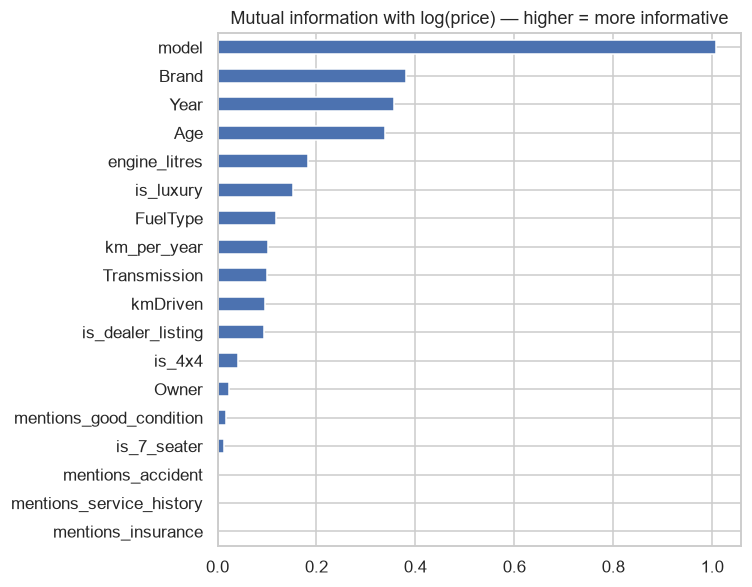

,mutual_info
model,1.01
Brand,0.38
Year,0.36
Age,0.34
engine_litres,0.18
is_luxury,0.15
FuelType,0.12
km_per_year,0.10
Transmission,0.10
kmDriven,0.10


In [23]:
# Feature selection support: mutual information with log(price)
candidates = (["Age", "Year", "kmDriven", "km_per_year", "engine_litres"]
              + CATEGORICAL_FEATURES + binary_candidates)
mi_data = df[candidates].copy()
mi_data[CATEGORICAL_FEATURES] = OrdinalEncoder().fit_transform(
    mi_data[CATEGORICAL_FEATURES].fillna("Unknown").astype(str))
mi_data = mi_data.fillna(mi_data.median(numeric_only=True))
discrete_mask = [c in CATEGORICAL_FEATURES + binary_candidates for c in candidates]

mi = pd.Series(mutual_info_regression(mi_data, np.log1p(df[TARGET]),
                                      discrete_features=discrete_mask,
                                      random_state=RANDOM_STATE),
               index=candidates).sort_values()
mi.plot.barh(figsize=(7, 5.5), title="Mutual information with log(price) — higher = more informative")
save_fig("mutual_information"); plt.show()
display(mi.sort_values(ascending=False).to_frame("mutual_info"))

### Feature selection — decisions and justification

| Column | Decision | Reason |
|---|---|---|
| `Age` | keep | Strongest numeric driver of price (EDA 4.2, high mutual information) |
| `Year` | drop | Exact duplicate of `Age` (Age = 2024 − Year) — keeping both double-counts one signal |
| `kmDriven`, `km_per_year` | keep | Usage lowers price; `km_per_year` adds usage *intensity* |
| `engine_litres` | keep | Strong correlation with price and varies within a model; missing values median-imputed |
| `Brand`, `model` | keep | Highest mutual information; rare models grouped as "infrequent" when encoded |
| `Transmission`, `FuelType`, `Owner` | keep | Clear price differences between groups (EDA 4.3) |
| `is_luxury`, `is_4x4`, `is_7_seater`, `is_dealer_listing`, `mentions_good_condition` | keep | Each separates prices clearly and appears in enough listings to learn from |
| `mentions_service_history`, `mentions_insurance`, `mentions_accident` | drop | Appear in only a handful of listings (see the share column above) — too rare to learn from, near-zero mutual information |
| `PostedDate` | drop | Almost all listings from a few months; no trend to learn (EDA 4.6) |
| `AdditionInfo` (raw text) | drop | Replaced by the extracted features above |

**Encoding:** categorical columns are one-hot encoded (`OneHotEncoder` with `min_frequency=10` so rare models share one column and unseen categories at prediction time don't crash the model). Numeric columns are median-imputed and standardised (needed for Ridge regression; harmless for trees).

## 6. Model Development

In [24]:
X = df[MODEL_FEATURES]
y = df[TARGET]

# Stratify on price quintiles so train and test have the same price mix
price_bins = pd.qcut(y, q=5, labels=False, duplicates="drop")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=price_bins)
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows | Features: {X.shape[1]}")

Train: 10,872 rows | Test: 2,719 rows | Features: 14


In [25]:
def make_preprocessor():
    """Impute + scale numbers, impute + one-hot encode categories, pass binary flags."""
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                            ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                     min_frequency=10, sparse_output=False))])
    return ColumnTransformer([("num", numeric, NUMERIC_FEATURES),
                              ("cat", categorical, CATEGORICAL_FEATURES),
                              ("bin", "passthrough", BINARY_FEATURES)])


def make_model(estimator):
    """Full pipeline: preprocessing -> model, trained on log(price), predicting ₹."""
    pipe = Pipeline([("prep", make_preprocessor()), ("model", estimator)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)


models = {
    "Baseline: predict mean": make_model(DummyRegressor(strategy="mean")),
    "Ridge regression": make_model(Ridge(alpha=1.0)),
    "Random forest": make_model(RandomForestRegressor(
        n_estimators=200, min_samples_leaf=2, max_features=0.3, n_jobs=-1, random_state=RANDOM_STATE)),
    "Gradient boosting": make_model(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
}

**Models compared:**
- **Baseline — predict the mean:** the score to beat; any useful model must do better.
- **Ridge regression:** simple linear baseline; interpretable, fast.
- **Random forest:** averages many decision trees; captures non-linear effects and interactions (e.g. luxury cars depreciate differently).
- **Gradient boosting (HistGradientBoosting):** builds trees sequentially, each correcting the previous one's errors; usually the strongest on tabular data.

**Validation:** 5-fold cross-validation on the training set to compare models fairly, then one final check on the untouched 20% test set.

In [26]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

cv_rows = []
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring,
                         return_train_score=True, n_jobs=-1)
    cv_rows.append({"model": name,
                    "CV RMSE": -res["test_rmse"].mean(), "CV RMSE std": res["test_rmse"].std(),
                    "CV MAE": -res["test_mae"].mean(),
                    "CV R²": res["test_r2"].mean(), "Train R²": res["train_r2"].mean()})
    print(f"✓ {name}")

cv_results = pd.DataFrame(cv_rows).set_index("model")
display(cv_results.style.format({"CV RMSE": "₹{:,.0f}", "CV RMSE std": "₹{:,.0f}",
                                 "CV MAE": "₹{:,.0f}", "CV R²": "{:.3f}", "Train R²": "{:.3f}"}))

✓ Baseline: predict mean
✓ Ridge regression
✓ Random forest
✓ Gradient boosting


,CV RMSE,CV RMSE std,CV MAE,CV R²,Train R²
model,,,,,
Baseline: predict mean,"₹1,453,532","₹98,051","₹631,856",-0.067,-0.066
Ridge regression,"₹774,926","₹115,745","₹228,894",0.696,0.707
Random forest,"₹778,544","₹130,370","₹224,763",0.693,0.821
Gradient boosting,"₹743,779","₹130,067","₹223,991",0.719,0.779


,RMSE,MAE,R²,Median % error
Baseline: predict mean,"₹1,494,284","₹652,974",-0.070,53.8%
Ridge regression,"₹705,927","₹224,808",0.761,14.0%
Random forest,"₹700,942","₹221,870",0.765,14.8%
Gradient boosting,"₹691,770","₹219,305",0.771,14.6%


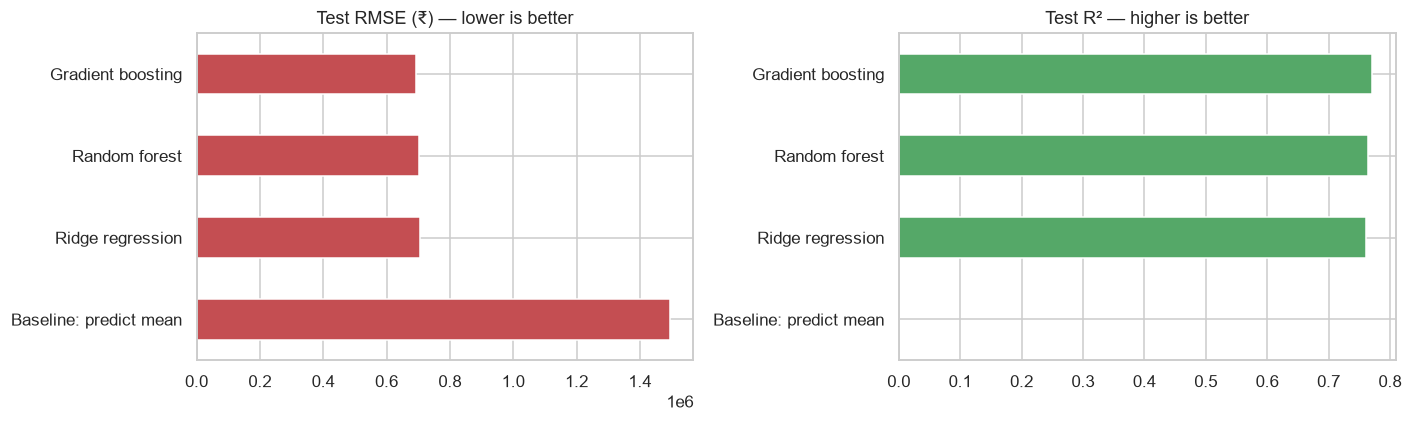

In [27]:
def evaluate(model, X_, y_):
    pred = model.predict(X_)
    return {"RMSE": np.sqrt(mean_squared_error(y_, pred)),
            "MAE": mean_absolute_error(y_, pred),
            "R²": r2_score(y_, pred),
            "Median % error": np.median(np.abs(pred - y_) / y_) * 100}

test_rows = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    test_rows[name] = evaluate(model, X_test, y_test)

test_results = pd.DataFrame(test_rows).T
display(test_results.style.format({"RMSE": "₹{:,.0f}", "MAE": "₹{:,.0f}",
                                   "R²": "{:.3f}", "Median % error": "{:.1f}%"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
test_results["RMSE"].plot.barh(ax=axes[0], color="C3", title="Test RMSE (₹) — lower is better")
test_results["R²"].clip(lower=0).plot.barh(ax=axes[1], color="C2", title="Test R² — higher is better")
save_fig("model_comparison"); plt.show()

**Interpreting the metrics**
- **RMSE** is the typical size of an error in ₹, weighted towards large mistakes — so it is dominated by expensive cars.
- **MAE** is the average absolute error in ₹ — easier to explain ("on average we're off by ₹X").
- **R²** is the share of price variation explained: 0 = no better than guessing the mean (the baseline scores ≈ 0 by design), 1 = perfect.
- **Median % error** says that half of all predictions are within this percentage of the true price.

Compare every model with the mean baseline: the gap shows how much the features actually explain. Tree-based models often beat Ridge on car prices because effects are non-linear and interact (e.g. age matters differently for luxury and budget cars). 

**What our results show:**
- Every model beats the mean baseline by a wide margin: the baseline's median error is ~54%, while the real models get to **~14%**.
- **Ridge is surprisingly competitive** (test R² 0.76, the lowest median error before tuning). Once price is on a log scale, much of the relationship is close to linear: each year of age removes a roughly constant *percentage* of value.
- The **untuned tree models only edge ahead** of Ridge (gradient boosting test R² 0.77), which is why tuning matters (Section 7).

## 7. Hyperparameter Tuning

Gradient boosting is tuned with `RandomizedSearchCV` (15 random combinations, 3-fold CV) because it has the most hyperparameters that change its behaviour. Random search covers a wide grid much faster than `GridSearchCV`. The final model is then chosen purely by cross-validated RMSE across *all* candidates, tuned or not. ⏱️ The search cell takes a few minutes.

In [28]:
param_distributions = {
    "regressor__model__learning_rate": [0.03, 0.05, 0.08, 0.1, 0.15],
    "regressor__model__max_iter": [300, 600],
    "regressor__model__max_leaf_nodes": [15, 31, 63],
    "regressor__model__min_samples_leaf": [5, 10, 20, 40],
    "regressor__model__l2_regularization": [0.0, 0.1, 0.5, 1.0, 3.0],
}

search = RandomizedSearchCV(
    make_model(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
    param_distributions=param_distributions, n_iter=15, cv=3,
    scoring="neg_root_mean_squared_error", n_jobs=-1, random_state=RANDOM_STATE, verbose=1)
search.fit(X_train, y_train)

print("Best parameters:")
for k, v in search.best_params_.items():
    print(f"  {k.split('__')[-1]}: {v}")

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best parameters:
  min_samples_leaf: 10
  max_leaf_nodes: 15
  max_iter: 600
  learning_rate: 0.08
  l2_regularization: 0.1


,CV RMSE,CV R²,Test RMSE,Test R²
Gradient boosting (default),"₹743,779",0.719,"₹691,770",0.771
Gradient boosting (tuned),"₹689,694",0.758,"₹630,679",0.809


Cross-validated RMSE changed by +7.3% after tuning (improvement).


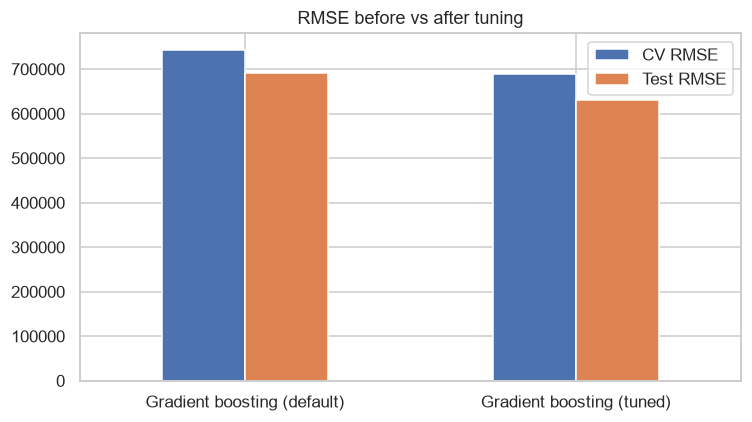

In [29]:
# Before vs after tuning — same 5-fold CV and same test set
tuned = search.best_estimator_
tuned_cv = cross_validate(tuned, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
tuned_test = evaluate(tuned, X_test, y_test)

comparison = pd.DataFrame({
    "Gradient boosting (default)": {"CV RMSE": cv_results.loc["Gradient boosting", "CV RMSE"],
                                    "CV R²": cv_results.loc["Gradient boosting", "CV R²"],
                                    "Test RMSE": test_results.loc["Gradient boosting", "RMSE"],
                                    "Test R²": test_results.loc["Gradient boosting", "R²"]},
    "Gradient boosting (tuned)": {"CV RMSE": -tuned_cv["test_rmse"].mean(),
                                  "CV R²": tuned_cv["test_r2"].mean(),
                                  "Test RMSE": tuned_test["RMSE"], "Test R²": tuned_test["R²"]},
}).T
display(comparison.style.format({"CV RMSE": "₹{:,.0f}", "Test RMSE": "₹{:,.0f}",
                                 "CV R²": "{:.3f}", "Test R²": "{:.3f}"}))

change = 1 - comparison.iloc[1]["CV RMSE"] / comparison.iloc[0]["CV RMSE"]
print(f"Cross-validated RMSE changed by {change:+.1%} after tuning "
      f"({'improvement' if change > 0 else 'no improvement'}).")

comparison[["CV RMSE", "Test RMSE"]].plot.bar(figsize=(7, 4), rot=0, title="RMSE before vs after tuning")
save_fig("tuning_comparison"); plt.show()

In [30]:
# Pick the final model: lowest cross-validated RMSE among all candidates
candidates_cv = cv_results["CV RMSE"].to_dict()
candidates_cv["Gradient boosting (tuned)"] = -tuned_cv["test_rmse"].mean()
fitted = {**models, "Gradient boosting (tuned)": tuned}

final_name = min(candidates_cv, key=candidates_cv.get)
final_model = fitted[final_name]
final_metrics = evaluate(final_model, X_test, y_test)
print(f"Final model: {final_name}")
for k, v in final_metrics.items():
    print(f"  Test {k}: {rupees(v) if k in ('RMSE', 'MAE') else f'{v:.3f}' if k == 'R²' else f'{v:.1f}%'}")

Final model: Gradient boosting (tuned)
  Test RMSE: ₹630,679
  Test MAE: ₹196,666
  Test R²: 0.809
  Test Median % error: 13.3%


## 8. Error Analysis

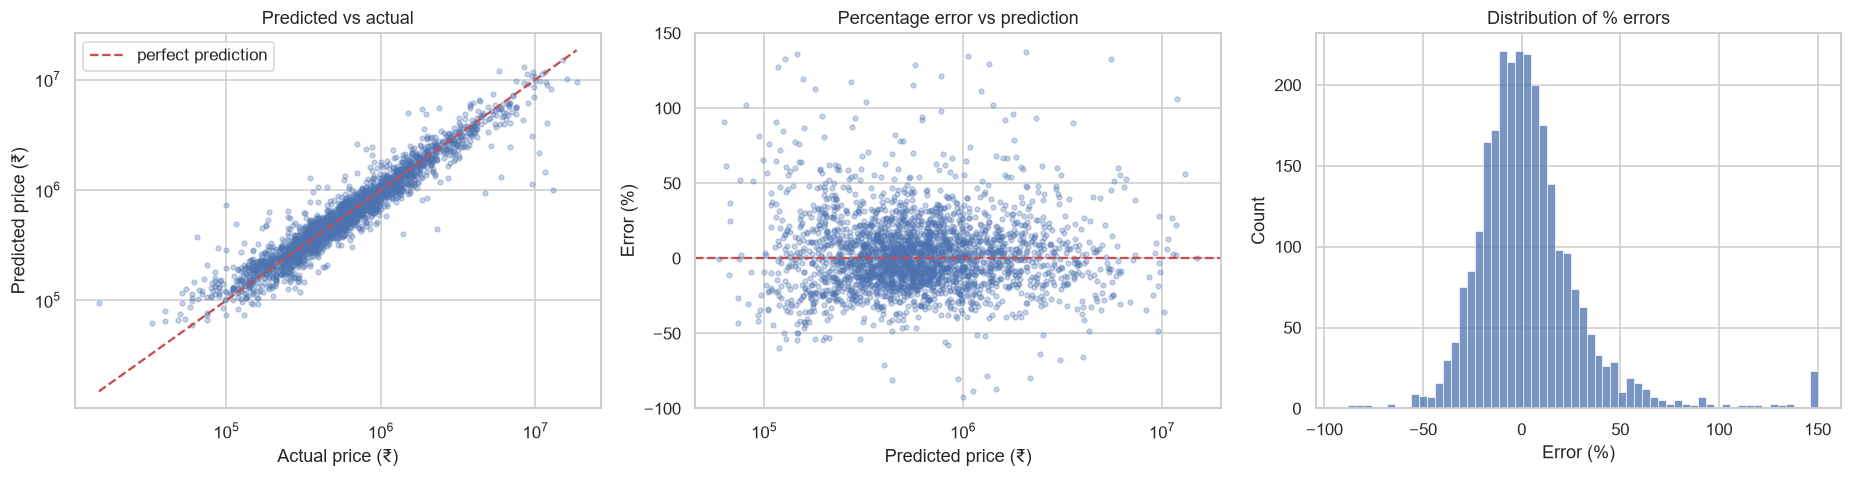

Predictions within ±10%: 39.3% | within ±20%: 67.2% | within ±30%: 82.8%


In [31]:
pred_test = final_model.predict(X_test)
residuals = y_test - pred_test
pct_error = (pred_test - y_test) / y_test * 100

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(y_test, pred_test, alpha=0.3, s=10)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "r--", label="perfect prediction")
axes[0].set(xscale="log", yscale="log", xlabel="Actual price (₹)", ylabel="Predicted price (₹)",
            title="Predicted vs actual"); axes[0].legend()

axes[1].scatter(pred_test, pct_error, alpha=0.3, s=10)
axes[1].axhline(0, color="r", ls="--")
axes[1].set(xscale="log", xlabel="Predicted price (₹)", ylabel="Error (%)",
            title="Percentage error vs prediction", ylim=(-100, 150))

sns.histplot(pct_error.clip(-100, 150), bins=60, ax=axes[2])
axes[2].set(title="Distribution of % errors", xlabel="Error (%)")
save_fig("error_analysis"); plt.show()
print(f"Predictions within ±10%: {(pct_error.abs() <= 10).mean():.1%} | "
      f"within ±20%: {(pct_error.abs() <= 20).mean():.1%} | "
      f"within ±30%: {(pct_error.abs() <= 30).mean():.1%}")

In [32]:
# Where does the model struggle? Error by price band and by brand
eval_df = X_test.assign(actual=y_test, predicted=pred_test,
                        abs_pct_error=np.abs(pct_error),
                        AdditionInfo=df.loc[X_test.index, "AdditionInfo"])
eval_df["price_band"] = pd.qcut(eval_df["actual"], 5,
                                labels=["Cheapest 20%", "Low", "Mid", "High", "Most expensive 20%"])

band = eval_df.groupby("price_band", observed=True).agg(
    listings=("actual", "size"),
    MAE=("actual", lambda s: mean_absolute_error(s, eval_df.loc[s.index, "predicted"])),
    median_pct_error=("abs_pct_error", "median"))
display(band.style.format({"MAE": "₹{:,.0f}", "median_pct_error": "{:.1f}%"}))

brand_err = (eval_df.groupby("Brand").agg(listings=("actual", "size"),
                                          median_pct_error=("abs_pct_error", "median"))
             .query("listings >= 15").sort_values("median_pct_error", ascending=False))
display(brand_err.head(10).style.format({"median_pct_error": "{:.1f}%"}))

,listings,MAE,median_pct_error
price_band,,,
Cheapest 20%,551,"₹51,931",21.1%
Low,545,"₹63,201",12.1%
Mid,535,"₹81,351",10.9%
High,545,"₹145,605",11.8%
Most expensive 20%,543,"₹642,354",14.4%


,listings,median_pct_error
Brand,,
Land Rover,20,29.1%
Audi,56,19.3%
Mahindra,140,19.1%
Chevrolet,22,18.2%
Mercedes-Benz,104,16.4%
Tata,124,15.6%
Nissan,20,14.6%
Volkswagen,89,14.2%
Hyundai,453,13.5%


In [33]:
# The 10 worst predictions — read the seller's text for clues
worst = eval_df.sort_values("abs_pct_error", ascending=False).head(10)
display(worst[["Brand", "model", "Age", "kmDriven", "actual", "predicted", "abs_pct_error", "AdditionInfo"]]
        .style.format({"actual": "₹{:,.0f}", "predicted": "₹{:,.0f}", "abs_pct_error": "{:.0f}%",
                       "kmDriven": "{:,.0f}"}))

,Brand,model,Age,kmDriven,actual,predicted,abs_pct_error,AdditionInfo
6654,Maruti Suzuki,Fronx,0.000000,nan,"₹100,000","₹730,708",631%,Maruti Suzuki Fronx 2024
1633,Mahindra,Marshal,24.000000,nan,"₹15,000","₹95,190",535%,Want NOC for Mahindra Marshal or Commander
11272,Tata,Punch EV,0.000000,225,"₹65,000","₹378,055",482%,Hindon vher
6181,Maruti Suzuki,Eeco,2.000000,"130,000","₹115,000","₹493,077",329%,Maruti Suzuki Eeco 2022 CNG & Hybrids 130000 Km Driven
8739,Toyota,Innova Hycross,0.000000,"1,234","₹700,000","₹2,592,164",270%,"Toyota Innova Hycross 2.0 VX (O) Hybrid 7 STR, 2024, Petrol"
5479,Tata,tata-punch,1.000000,"30,000","₹350,000","₹1,287,951",268%,Tata Punch 2023 Diesel 30000 Km Driven
774,Hyundai,Verna,16.000000,"140,000","₹88,000","₹298,652",239%,"Hyundai Verna 1.5 SX Diesel AT, 2008, Diesel"
6266,Hyundai,Aura,0.000000,nan,"₹190,000","₹635,764",235%,"Hyundai Aura 1.2 S CNG, 2024, CNG & Hybrids"
5885,Ford,Endeavour,3.000000,nan,"₹1,500,000","₹4,943,216",230%,2021 Ford Endeavour Titanium Plus 2.0 4x4 AT
6115,Mercedes-Benz,A Class,10.000000,"35,000","₹799,000","₹2,370,213",197%,"Mercedes-Benz A Class, 2014, Diesel"


,Train R²,CV R²,Gap (train − CV)
model,,,
Baseline: predict mean,-0.066,-0.067,0.000
Ridge regression,0.707,0.696,0.011
Random forest,0.821,0.693,0.128
Gradient boosting,0.779,0.719,0.060
Gradient boosting (tuned),0.822,0.758,0.064


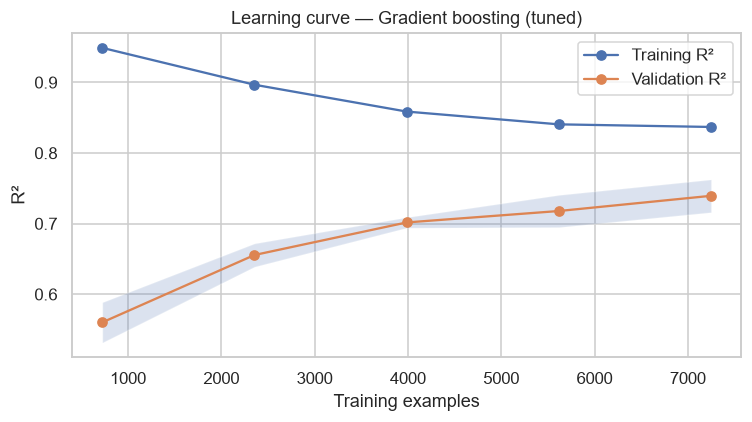

In [34]:
# Overfitting / underfitting check: training vs validation performance
fit_check = cv_results[["Train R²", "CV R²"]].copy()
fit_check.loc["Gradient boosting (tuned)"] = [r2_score(y_train, tuned.predict(X_train)),
                                              tuned_cv["test_r2"].mean()]
fit_check["Gap (train − CV)"] = fit_check["Train R²"] - fit_check["CV R²"]
display(fit_check.style.format("{:.3f}"))

# Learning curve for the final model
sizes, train_sc, val_sc = learning_curve(
    final_model, X_train, y_train, cv=3, scoring="r2",
    train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=-1, shuffle=True, random_state=RANDOM_STATE)
plt.figure(figsize=(7, 4))
plt.plot(sizes, train_sc.mean(axis=1), "o-", label="Training R²")
plt.plot(sizes, val_sc.mean(axis=1), "o-", label="Validation R²")
plt.fill_between(sizes, val_sc.mean(1) - val_sc.std(1), val_sc.mean(1) + val_sc.std(1), alpha=0.2)
plt.xlabel("Training examples"); plt.ylabel("R²"); plt.legend()
plt.title(f"Learning curve — {final_name}"); save_fig("learning_curve"); plt.show()

**Reading the over/underfitting check**
- **Underfitting:** the mean baseline underfits completely (R² ≈ 0). Ridge has almost no train/validation gap (0.71 vs 0.70), but its ceiling is limited because it can only fit straight-line effects.
- **Overfitting:** the **random forest** shows the clearest overfitting — train R² 0.82 vs cross-validated 0.69 (gap 0.13). Its deep trees memorise individual training cars.
- **Final model:** tuned gradient boosting has a moderate gap (0.82 vs 0.76). The chosen settings (small trees with 15 leaves, at least 10 cars per leaf) act as regularisation.
- **Learning curve:** validation R² is **still rising** at the full training size. More listings would likely improve the model further, so it is data-limited rather than at its capacity.
- **Where it fails:**
  - The cheapest 20% of cars have the highest percentage error (~20% median vs ~12% elsewhere), because a small ₹ miss is a large % of a low price.
  - Luxury brands (Land Rover, Audi, Mercedes-Benz) are also harder to predict, since they have few examples and huge variation between variants.
- **The worst predictions are mostly bad listings, not model failures:**
  - A 2024 Maruti Fronx listed at ₹1 lakh is almost certainly a down-payment or EMI ad.
  - Other examples are a request for an NOC (a no-objection certificate, an official clearance document) and unreadable text.
  - No model can predict these from the listing details. They show what further data validation would be needed in a real system.

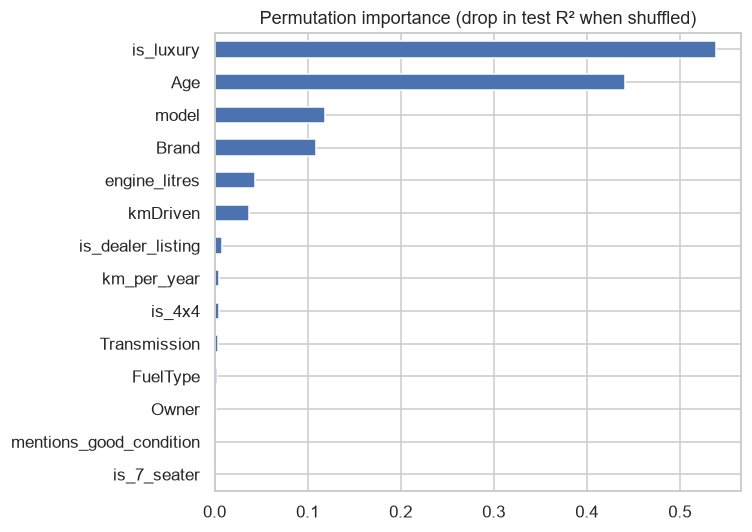

,R² drop
is_luxury,0.54
Age,0.44
model,0.12
Brand,0.11
engine_litres,0.04
kmDriven,0.04
is_dealer_listing,0.01
km_per_year,0.01
is_4x4,0.00
Transmission,0.00


In [35]:
# Which features matter most? Permutation importance on the test set
perm = permutation_importance(final_model, X_test, y_test, n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1, scoring="r2")
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
importance.plot.barh(figsize=(7, 5), title="Permutation importance (drop in test R² when shuffled)")
save_fig("feature_importance"); plt.show()
display(importance.sort_values(ascending=False).to_frame("R² drop"))

## 9. Save Final Model

The final pipeline (preprocessing + model) is refit on **all** cleaned data and saved, together with the dropdown values the Streamlit app needs.

In [36]:
final_model.fit(X, y)
joblib.dump(final_model, MODEL_DIR / "car_price_model.joblib")

app_metadata = {
    "model_name": final_name,
    "test_metrics": {k: float(v) for k, v in final_metrics.items()},
    "brands_models": {b: sorted(g["model"].dropna().unique().tolist())
                      for b, g in df.groupby("Brand")},
    "transmissions": sorted(df["Transmission"].dropna().unique().tolist()),
    "fuel_types": sorted(df["FuelType"].dropna().unique().tolist()),
    "owners": sorted(df["Owner"].dropna().unique().tolist()),
    "max_age": int(df["Age"].max()),
}
(MODEL_DIR / "app_metadata.json").write_text(json.dumps(app_metadata, indent=2))
print("Saved models/car_price_model.joblib and models/app_metadata.json")

Saved models/car_price_model.joblib and models/app_metadata.json


## 10. Insights & Conclusion

In [37]:
# Key numbers for the conclusion and slides (all computed above)
top3 = importance.sort_values(ascending=False).head(3).index.tolist()
baseline_rmse = test_results.loc["Baseline: predict mean", "RMSE"]
print(f"Dataset: {len(df):,} clean listings, {df['Brand'].nunique()} brands")
print(f"Median asking price: {rupees(df[TARGET].median())}")
print(f"Typical depreciation: ~{annual_drop:.0%} of value per year")
print(f"Final model: {final_name}")
print(f"  Test R² = {final_metrics['R²']:.3f} | RMSE = {rupees(final_metrics['RMSE'])} "
      f"| MAE = {rupees(final_metrics['MAE'])} | median error = {final_metrics['Median % error']:.1f}%")
print(f"  RMSE reduced by {1 - final_metrics['RMSE'] / baseline_rmse:.0%} vs. the mean baseline")
print(f"Most important features: {', '.join(top3)}")

Dataset: 13,591 clean listings, 38 brands
Median asking price: ₹560,000
Typical depreciation: ~12% of value per year
Final model: Gradient boosting (tuned)
  Test R² = 0.809 | RMSE = ₹630,679 | MAE = ₹196,666 | median error = 13.3%
  RMSE reduced by 58% vs. the mean baseline
Most important features: is_luxury, Age, model


### Key insights
1. **Age is the main price driver.** Asking prices fall by roughly **12% per year** of age.
2. **Brand and model set the price level.** Luxury brands list at about **4×** the median of other brands. `is_luxury`, `Age`, `model` and `Brand` are the four most important features (permutation importance).
3. **Transmission, fuel and ownership matter.** Automatics (₹7.75 lakh median vs ₹4.5 lakh for manuals), diesel cars and first-owner cars command a premium.
4. **The seller's text is a hidden goldmine.** It let us recover ~98% of missing brands and years with over 99% accuracy. It also gave new features such as engine size (34% coverage, Spearman 0.65 with price) and 4x4.

### Model performance
- The final model is **tuned gradient boosting**. On unseen test data it explains **81% of price variation (R² = 0.81)**.
- Its typical error (MAE) is **₹1.97 lakh**, and the median error is **13.3%**: half of all predictions are within about 13% of the asking price.
- This cuts RMSE by **58%** compared with predicting the average price.
- Hyperparameter tuning improved cross-validated RMSE by **7.3%** (test R² 0.77 → 0.81).

### Limitations
- The data does not record condition, location or exact variant/trim, which explain much of the remaining error.
- Listings are **asking** prices, not final sale prices. Some are not real car prices at all (down-payment ads, parts).
- Rare brands/models and luxury cars have few examples, so their predictions are less reliable.
- Listings come from a short time window, so the model will not track future market changes without retraining.

### Potential improvements
- Extract more from `AdditionInfo` using TF-IDF or sentence embeddings, and parse variant names like "VX" or "ZXi".
- Flag suspicious listings automatically (e.g. price far below the model's estimate for a near-new car) before training.
- Try target encoding for `model`, or CatBoost/LightGBM, which handle high-cardinality categories natively.
- Collect more listings, since the learning curve is still rising.
- Predict a price **range** (quantile regression) instead of a single number.

### Lessons learned
- Real-world data needs careful cleaning before any modelling. Duplicates, placeholders like "Unknown"/9999 and junk ads made up a large share of the raw rows (24,575 rows → 13,591 unique, usable listings).
- Free text that looks useless can be the most valuable column.
- A log-transformed target made a large difference for skewed prices.
- Always compare against a naive baseline: it shows how much the model really adds.